
# Python for Financial Modeling

## Learning Objectives

- Download stock market data using yfinance
- Work with pandas DataFrames
- Perform arithmetic operations on columns
- Create financial features
- Calculate returns
- Calculate moving averages
- Use NumPy for financial calculations
- Visualize stock prices


In [15]:
!pip install yfinance -q


[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12,5)


In [30]:

# df = yf.download(
#     "AAPL",
#     start="2023-01-01",
#     end="2025-01-01",
#     auto_adjust=True
# )

# df.head()


In [31]:

df = yf.download(
    "AAPL",
    start="2023-01-01",
    end="2025-01-01",
    auto_adjust=True
)

# Handle new yfinance format
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

print(df.columns)
df.head()

[*********************100%***********************]  1 of 1 completed

Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='object', name='Price')


Price,Close,High,Low,Open,Volume
Date,,,,,
2023-01-03,122.982727,128.715425,122.097746,128.105777,112117500
2023-01-04,124.251205,126.512824,122.992568,124.772359,89113600
2023-01-05,122.933556,125.637661,122.677900,125.008343,80962700
2023-01-06,127.456772,128.115588,122.805715,123.907026,87754700
2023-01-09,127.977951,131.183555,127.722296,128.292618,70790800



## Understanding the Columns

- Open: Price at market open
- High: Highest price during the day
- Low: Lowest price during the day
- Close: Price at market close
- Volume: Number of shares traded


In [32]:

df.shape
df.columns
df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 502 entries, 2023-01-03 to 2024-12-31
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   502 non-null    float64
 1   High    502 non-null    float64
 2   Low     502 non-null    float64
 3   Open    502 non-null    float64
 4   Volume  502 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 23.5 KB


Price,Close,High,Low,Open,Volume
count,502.000000,502.000000,502.000000,502.000000,5.020000e+02
mean,187.896248,189.387127,186.136365,187.626463,5.816095e+07
std,28.062066,28.203120,27.821258,28.056515,2.512372e+07
min,122.933556,125.637661,122.097746,123.907026,2.323470e+07
25%,169.785686,171.405378,168.538165,169.863031,4.495800e+07
50%,183.135078,184.472893,181.520296,183.078692,5.250285e+07
75%,212.437260,215.194180,210.137215,212.657878,6.489808e+07
max,257.375580,258.448740,255.994420,256.550862,3.186799e+08


In [33]:

df["Close"].head()
df[["Open","Close"]].head()


Price,Open,Close
Date,,
2023-01-03,128.105777,122.982727
2023-01-04,124.772359,124.251205
2023-01-05,125.008343,122.933556
2023-01-06,123.907026,127.456772
2023-01-09,128.292618,127.977951


In [34]:

df["High_Low_Sum"] = df["High"] + df["Low"]
df["Range"] = df["High"] - df["Low"]
df["Dollar_Volume"] = df["Close"] * df["Volume"]
df["High_Low_Ratio"] = df["High"] / df["Low"]

df.head()


Price,Close,High,Low,Open,Volume,High_Low_Sum,Range,Dollar_Volume,High_Low_Ratio
Date,,,,,,,,,
2023-01-03,122.982727,128.715425,122.097746,128.105777,112117500,250.813171,6.617680,1.378852e+10,1.054200
2023-01-04,124.251205,126.512824,122.992568,124.772359,89113600,249.505393,3.520256,1.107247e+10,1.028622
2023-01-05,122.933556,125.637661,122.677900,125.008343,80962700,248.315561,2.959761,9.953033e+09,1.024126
2023-01-06,127.456772,128.115588,122.805715,123.907026,87754700,250.921303,5.309874,1.118493e+10,1.043238
2023-01-09,127.977951,131.183555,127.722296,128.292618,70790800,258.905851,3.461260,9.059662e+09,1.027100


In [35]:

prices = df["Close"].values

print("Mean Price:", np.mean(prices))
print("Std Dev:", np.std(prices))


Mean Price: 187.89624763579957
Std Dev: 28.034101421851872



## Daily Returns

Investors usually analyze returns rather than prices.


In [36]:

df["Daily_Return"] = df["Close"].pct_change()

print("Average Return:", df["Daily_Return"].mean())
print("Volatility:", df["Daily_Return"].std())


Average Return: 0.0014976236697111886
Volatility: 0.013451986660322561


In [37]:

df["Cumulative_Return"] = (1 + df["Daily_Return"]).cumprod()

df[["Daily_Return","Cumulative_Return"]].tail()


Price,Daily_Return,Cumulative_Return
Date,,
2024-12-24,0.011478,2.086153
2024-12-26,0.003176,2.092778
2024-12-27,-0.013242,2.065066
2024-12-30,-0.013263,2.037676
2024-12-31,-0.007058,2.023294


In [38]:

df["MA20"] = df["Close"].rolling(20).mean()
df["MA50"] = df["Close"].rolling(50).mean()


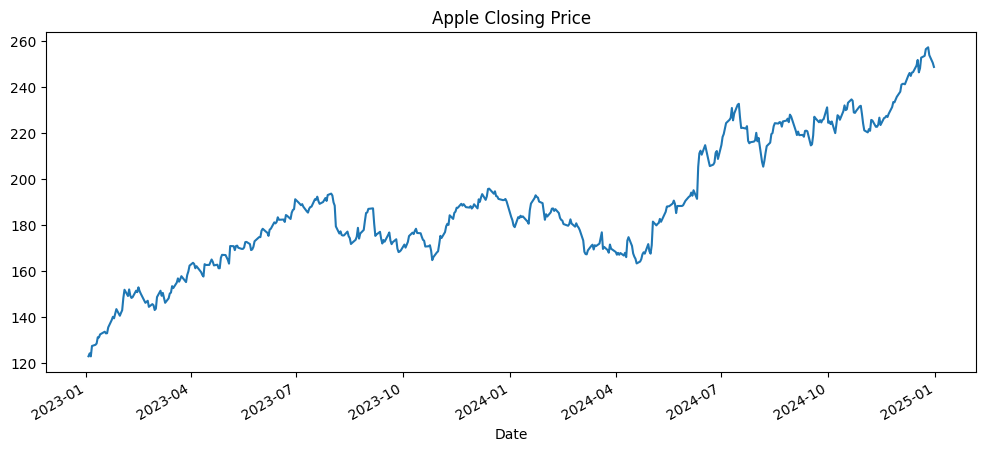

In [39]:

df["Close"].plot(title="Apple Closing Price")
plt.show()


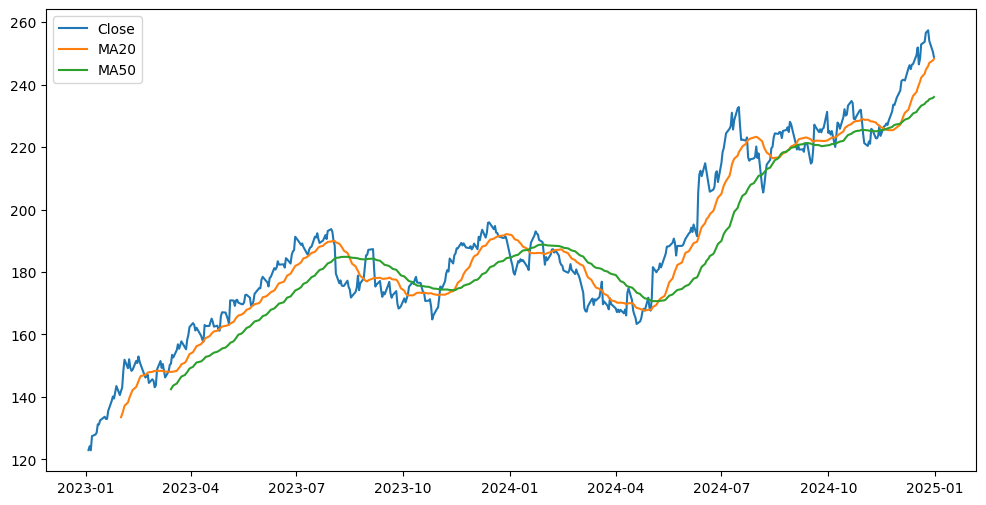

In [40]:

plt.figure(figsize=(12,6))

plt.plot(df["Close"], label="Close")
plt.plot(df["MA20"], label="MA20")
plt.plot(df["MA50"], label="MA50")

plt.legend()
plt.show()


In [41]:

print("Maximum Price:", df["Close"].max())
print("Minimum Price:", df["Close"].min())
print("Positive Days:", (df["Daily_Return"] > 0).sum())
print("Negative Days:", (df["Daily_Return"] < 0).sum())


Maximum Price: 257.3755798339844
Minimum Price: 122.93355560302734
Positive Days: 282
Negative Days: 217


In [42]:

df["Signal"] = np.where(
    df["Close"] > df["MA20"],
    "BUY",
    "SELL"
)

df[["Close","MA20","Signal"]].tail()


Price,Close,MA20,Signal
Date,,,
2024-12-24,256.560822,244.729908,BUY
2024-12-26,257.375580,245.920301,BUY
2024-12-27,253.967392,246.946744,BUY
2024-12-30,250.598907,247.685524,BUY
2024-12-31,248.830200,248.223586,BUY


In [43]:

df["Month"] = df.index.month

df.groupby("Month")["Daily_Return"].mean()


Month
1     0.002606
2     0.000186
3     0.001495
4     0.000624
5     0.003908
6     0.004668
7     0.001639
8    -0.000139
9    -0.001782
10   -0.000675
11    0.003909
12    0.001685
Name: Daily_Return, dtype: float64


# What We Learned

### Pandas
- DataFrames
- Column selection
- New column creation
- GroupBy
- Descriptive statistics

### NumPy
- Arrays
- Mean
- Standard deviation
- Vectorized calculations

### Finance Concepts
- Stock prices
- Returns
- Volatility
- Moving averages
- Trading signals
- Cumulative returns
